# 02 · Part I: valuing FN FS9548 as an agency MBS

Full and timely payment of scheduled principal and interest is assumed to be guaranteed by the U.S.
government, so the only risks are interest-rate and prepayment risk. Steps 2–4 of the assignment:

* **Step 2:** prepayment model (PSA with a refinancing overlay);
* **Step 3:** cash flows along each of the 10,000 rate paths from notebook 01;
* **Step 4:** value = average of path present values; is the security fairly priced, and how sure are we?

In [1]:
import sys
import json
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import mbs_model as m
import plot_style as ps

ps.apply()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

case = m.build_base_case()
inputs, paths = case["inputs"], case["paths"]
T, B0 = inputs["wam_months"], inputs["current_balance"]
lag = inputs["payment_lag_months_after_month_start"]
mkt = m.market_prices(inputs)
AI = m.accrued_interest(inputs)
base = m.BASE

## Step 2 · Prepayment model

**PSA benchmark.** $\text{CPR}_t = 6\% \times \min(\text{age}_t, 30)/30$ at 100 PSA, scaled by the PSA speed,
and converted to a monthly rate $\text{SMM}_t = 1 - (1-\text{CPR}_t)^{1/12}$. The pool is 125 months seasoned,
so it is past the 30-month ramp and 100 PSA = 6% CPR throughout.

**Base speed: 178 PSA (10.68% CPR).** This is Bloomberg's projected speed for the pool (BAM model, shown on the
BVAL/ALLQ screens). Realised speeds have been faster (1-year 15.5% CPR ≈ 258 PSA), but the pool's 3.45% WAC is far
below current mortgage rates, so refinancing is uneconomic and prepayments come mainly from housing turnover;
a forward projection below the recent realised speed is reasonable. 258 PSA is included as a sensitivity.

In [2]:
hist = pd.DataFrame({"CPR": inputs["historical_cpr"], "PSA": inputs["historical_psa"]})
hist.loc["Bloomberg projection"] = [0.06 * base["psa"], base["psa"]]
hist

,CPR,PSA
1m,0.2700,4.4900
3m,0.2010,3.3500
6m,0.1710,2.8500
1y,0.1550,2.5800
life,0.1650,2.7500
Bloomberg projection,0.1068,1.7800


**Refinancing overlay: why the cash flows must differ by path.** With a pure PSA model the cash flows are the
same on every path, and because the paths are calibrated to the Treasury curve the Monte Carlo value collapses to
simple discounting on the zero curve. The prepayment option would then have no value. To make cash flows
path-dependent (as Step 3 requires) the PSA speed in month $t$ is scaled by the change in long rates since the
valuation date, $\Delta_t = \sigma W_{t-1}$:

$$\text{PSA}_t = 178\% \times \min\!\big(1.75,\ \max(0.75,\ 1 - \beta\,\Delta_t / 1\%)\big), \qquad \beta = 0.20$$

A 100 bp fall in rates raises the speed by 20% (≈ 214 PSA); a 100 bp rise slows it by 20% (lock-in). The
response is deliberately modest because even a 150 bp rally leaves this 3.45% WAC pool out of the money.
$\beta$ is an assumption, so $\beta = 0$ and $\beta = 0.4$ are shown as sensitivities.

In [3]:
cf = m.project_cash_flows(inputs, base["psa"], paths.shock, base["beta"])
psa_eff = cf.cpr / 0.06
pct = np.percentile(psa_eff * 100, [5, 50, 95], axis=0)
pd.DataFrame({"month": [1, 12, 24, 36, 52],
              "PSA 5th pct": pct[0][[0, 11, 23, 35, 51]],
              "PSA median": pct[1][[0, 11, 23, 35, 51]],
              "PSA 95th pct": pct[2][[0, 11, 23, 35, 51]]})

,month,PSA 5th pct,PSA median,PSA 95th pct
0,1,178.0000,178.0000,178.0000
1,12,133.5000,178.0000,226.9350
2,24,133.5000,178.0000,247.9469
3,36,133.5000,178.0000,263.7542
4,52,133.5000,178.0000,282.2488


## Step 3 · Cash flows along each path

For each path and month $t = 1..52$, with beginning balance $B_{t-1}$ and remaining term $n_t = 52 - t + 1$:

| Item | Formula |
|---|---|
| Scheduled mortgage payment | $\text{PMT}_t = B_{t-1}\,\dfrac{\text{WAC}/12}{1-(1+\text{WAC}/12)^{-n_t}}$ |
| Gross interest (borrowers) | $B_{t-1}\,\text{WAC}/12$ |
| Investor interest (pass-through) | $B_{t-1}\times 3.00\%/12$ |
| Scheduled principal | $\text{PMT}_t - B_{t-1}\,\text{WAC}/12$ |
| Prepayment | $\text{SMM}_t\,(B_{t-1} - \text{scheduled principal}_t)$ |
| Investor cash flow | investor interest + scheduled principal + prepayment |
| Ending balance | $B_t = B_{t-1}$ − scheduled principal − prepayment |

The 0.448% difference between WAC and the pass-through rate is the servicing and guarantee fee retained before
cash reaches investors. The first path's cash flows are shown below (the Excel workbook reproduces them with formulas).

In [4]:
path1 = pd.DataFrame({
    "month": np.arange(1, T + 1),
    "begin balance": cf.begin_balance[0],
    "PMT": cf.scheduled_payment[0],
    "investor interest": cf.investor_interest[0],
    "sched. principal": cf.scheduled_principal[0],
    "PSA": psa_eff[0],
    "SMM": cf.smm[0],
    "prepayment": cf.prepayment[0],
    "cash flow": cf.cash_flow[0],
    "end balance": cf.end_balance[0],
})
path1.head(6)

,month,begin balance,PMT,investor interest,sched. principal,PSA,SMM,prepayment,cash flow,end balance
0,1,"2,986,518.0000","61,912.7955","7,466.2950","53,331.5337",1.7800,0.0094,"27,477.8222","88,275.6509","2,905,708.6441"
1,2,"2,905,708.6441","61,332.8021","7,264.2716","52,983.7326",1.8512,0.0098,"27,852.3879","88,100.3920","2,824,872.5236"
2,3,"2,824,872.5236","60,733.9834","7,062.1813","52,617.1830",1.8296,0.0096,"26,733.6288","86,412.9931","2,745,521.7118"
3,4,"2,745,521.7118","60,148.3087","6,863.8043","52,259.5096",1.9997,0.0106,"28,534.5477","87,657.8617","2,664,727.6544"
4,5,"2,664,727.6544","59,511.0500","6,661.8191","51,854.3992",1.8745,0.0099,"25,850.3665","84,366.5848","2,587,022.8887"
5,6,"2,587,022.8887","58,922.2796","6,467.5572","51,488.9005",1.8172,0.0096,"24,276.6094","82,233.0671","2,511,257.3788"


In [5]:
path1.tail(3)

,month,begin balance,PMT,investor interest,sched. principal,PSA,SMM,prepayment,cash flow,end balance
49,50,"117,066.6115","39,246.6659",292.6665,"38,910.2945",1.3350,0.0069,541.8873,"39,744.8483","77,614.4297"
50,51,"77,614.4297","38,974.5539",194.0361,"38,751.5418",1.3350,0.0069,269.4511,"39,215.0290","38,593.4368"
51,52,"38,593.4368","38,704.3286",96.4836,"38,593.4368",1.3350,0.0069,0.0000,"38,689.9204",0.0000


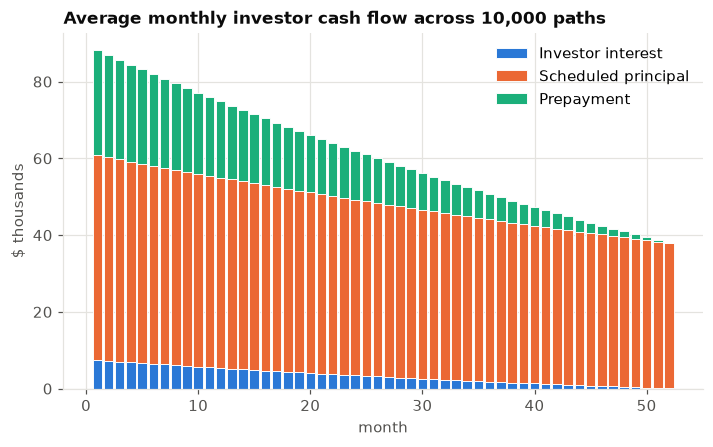

In [6]:
mean_parts = pd.DataFrame({
    "Investor interest": cf.investor_interest.mean(0),
    "Scheduled principal": cf.scheduled_principal.mean(0),
    "Prepayment": cf.prepayment.mean(0),
}, index=np.arange(1, T + 1))
fig, ax = plt.subplots()
bottom = np.zeros(T)
for col, color in zip(mean_parts, [ps.BLUE, ps.ORANGE, "#1baf7a"]):
    ax.bar(mean_parts.index, mean_parts[col] / 1e3, bottom=bottom / 1e3, color=color, width=0.85,
           label=col, edgecolor="white", linewidth=0.6)
    bottom += mean_parts[col].values
ax.set_xlabel("month")
ax.set_ylabel("$ thousands")
ax.set_title("Average monthly investor cash flow across 10,000 paths")
ax.legend(loc="upper right")
ps.save(fig, "04_cash_flow_composition")

## Step 4 · Value = average discounted value across paths

Each path is discounted with **its own** cumulative short-rate discount factors, evaluated on the actual payment
date. The cash flow for accrual month $t$ is paid on the 25th of the following month (54-day stated delay),
i.e. $25/30$ of a month after the end of month $t-1$:

$$\text{DF}^{(i)}_t = \prod_{k=0}^{t-2}\frac{1}{1+r_k^{(i)}/12}\times\left(1+\frac{r_{t-1}^{(i)}}{12}\right)^{-25/30},
\qquad \text{PV}^{(i)} = \sum_{t=1}^{52}\text{CF}^{(i)}_t\,\text{DF}^{(i)}_t,
\qquad V = \frac{1}{N}\sum_{i=1}^{N}\text{PV}^{(i)}.$$

$V/B_0\times 100$ is a *full* price; subtracting accrued interest (29/30 × 3%/12 × 100 = 0.2417) gives a clean
price comparable with the BVAL quote.

In [7]:
summary, prices, _ = m.value_agency(case)
oas = m.solve_oas(cf.cash_flow, paths.rates, B0, mkt["bid"] + AI, lag)
oas_mid = m.solve_oas(cf.cash_flow, paths.rates, B0, mkt["mid"] + AI, lag)
part1 = {
    "model_full_price": summary["full_price"],
    "accrued_interest": AI,
    "model_clean_price": summary["clean_price"],
    "std_error": summary["std_error"],
    "ci95_clean": [summary["ci_low"] - AI, summary["ci_high"] - AI],
    "market_bid": mkt["bid"],
    "market_mid": mkt["mid"],
    "model_minus_bid": summary["clean_price"] - mkt["bid"],
    "model_minus_mid": summary["clean_price"] - mkt["mid"],
    "oas_bp_at_bid": oas * 1e4,
    "oas_bp_at_mid": oas_mid * 1e4,
    "bloomberg_toas_bp": inputs["bloomberg_bam_toas_bp"],
    "n_paths": summary["n_paths"],
    "sigma_monthly": case["sigma"],
}
pd.Series(part1).to_frame("Part I result")

,Part I result
model_full_price,98.4397
accrued_interest,0.2417
model_clean_price,98.1980
std_error,0.0003
ci95_clean,"[98.19746, 98.198517]"
market_bid,97.7383
market_mid,97.7695
model_minus_bid,0.4597
model_minus_mid,0.4285
oas_bp_at_bid,25.6695


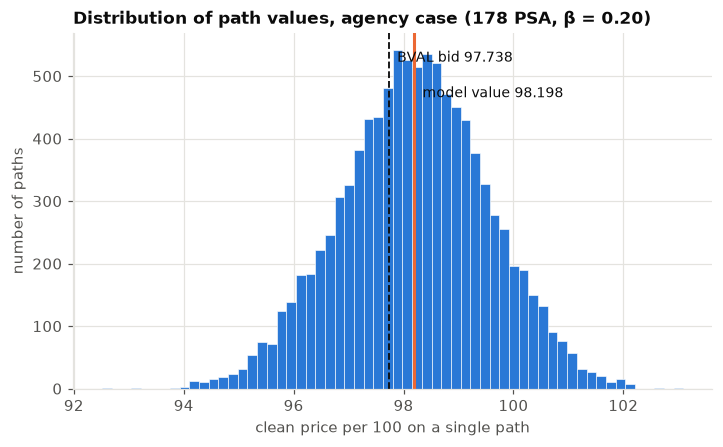

In [8]:
fig, ax = plt.subplots()
ax.hist(prices - AI, bins=60, color=ps.BLUE, edgecolor="white", linewidth=0.4)
ax.axvline(mkt["bid"], color=ps.INK, lw=1.2, ls="--")
ax.axvline(summary["clean_price"], color=ps.ORANGE, lw=2)
ymax = ax.get_ylim()[1]
ax.text(mkt["bid"], ymax * 0.95, f"  BVAL bid {mkt['bid']:.3f}", ha="left", va="top", color=ps.INK, fontsize=9)
ax.text(summary["clean_price"], ymax * 0.85, f"  model value {summary['clean_price']:.3f}", ha="left", va="top",
        color=ps.INK, fontsize=9)
ax.set_xlabel("clean price per 100 on a single path")
ax.set_ylabel("number of paths")
ax.set_title("Distribution of path values, agency case (178 PSA, β = 0.20)")
ps.save(fig, "05_path_value_distribution")

### Convergence: how many paths are enough?
The standard error with 10,000 antithetic paths is under 0.001 points. With only **100** independent paths
(as in the original Excel model) the standard error is about 0.13 points, so two runs can easily differ by
0.3–0.5 points. The original cheap/rich conclusions flipped between PSA speeds for exactly this reason.

s.e. with 100 independent paths ≈ 0.134; with 10,000 antithetic paths = 0.0003


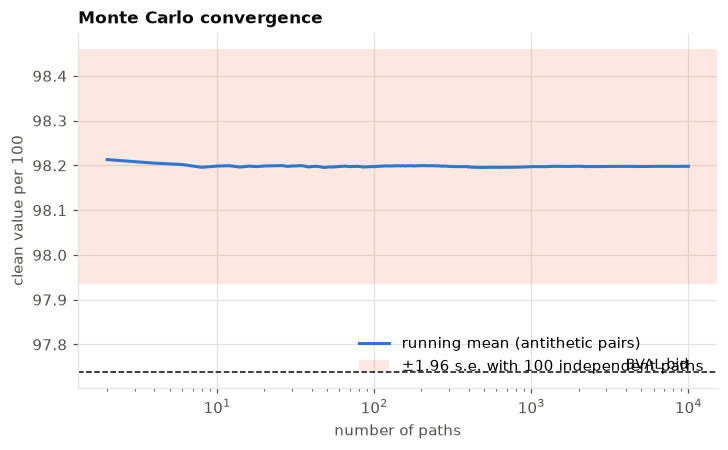

In [9]:
running = np.cumsum(0.5 * (prices[:5000] + prices[5000:])) / np.arange(1, 5001) - AI
se_100 = (prices - AI).std(ddof=1) / np.sqrt(100)
fig, ax = plt.subplots()
ax.plot(np.arange(1, 5001) * 2, running, color=ps.BLUE, label="running mean (antithetic pairs)")
ax.axhline(mkt["bid"], color=ps.INK, lw=1, ls="--")
ax.text(10000, mkt["bid"], "BVAL bid", ha="right", va="bottom", fontsize=9, color=ps.INK)
ax.axhspan(summary["clean_price"] - 1.96 * se_100, summary["clean_price"] + 1.96 * se_100,
           color=ps.ORANGE, alpha=0.15, lw=0, label="±1.96 s.e. with 100 independent paths")
ax.set_xscale("log")
ax.set_xlabel("number of paths")
ax.set_ylabel("clean value per 100")
ax.set_title("Monte Carlo convergence")
ax.legend(loc="lower right")
ps.save(fig, "06_convergence")
print(f"s.e. with 100 independent paths ≈ {se_100:.3f}; with 10,000 antithetic paths = {summary['std_error']:.4f}")

### Sensitivity analysis (same 10,000 paths in every case)
Common random numbers mean differences between rows reflect only the changed assumption, not simulation noise.

In [10]:
def row(label, s, cfs, rates=paths.rates):
    o = m.solve_oas(cfs, rates, B0, mkt["bid"] + AI, lag)
    return {"case": label, "clean value": s["clean_price"], "model − bid": s["clean_price"] - mkt["bid"],
            "OAS at bid (bp)": o * 1e4}

psa_rows = []
for psa in [1.00, 1.50, 1.78, 2.00, 2.58, 3.00]:
    s, _, c = m.value_agency(case, psa=psa)
    psa_rows.append(row(f"{psa*100:.0f} PSA", s, c.cash_flow))
psa_table = pd.DataFrame(psa_rows).set_index("case")
psa_table

,clean value,model − bid,OAS at bid (bp)
case,,,
100 PSA,98.0866,0.3483,18.1679
150 PSA,98.1586,0.4203,22.9011
178 PSA,98.1980,0.4597,25.6695
200 PSA,98.2285,0.4902,27.9064
258 PSA,98.3068,0.5686,34.0755
300 PSA,98.3619,0.6236,38.8017


In [11]:
beta_rows = []
for b in [0.0, 0.2, 0.4]:
    s, _, c = m.value_agency(case, beta=b)
    beta_rows.append(row(f"β = {b:.1f}", s, c.cash_flow))
beta_table = pd.DataFrame(beta_rows).set_index("case")
beta_table["option cost vs β=0"] = beta_table["clean value"].iloc[0] - beta_table["clean value"]
beta_table

,clean value,model − bid,OAS at bid (bp),option cost vs β=0
case,,,,
β = 0.0,98.2310,0.4927,27.4665,0.0000
β = 0.2,98.1980,0.4597,25.6695,0.0330
β = 0.4,98.1876,0.4493,25.2146,0.0434


In [12]:
vol_rows = []
for mult in [0.5, 1.0, 1.5]:
    c_v = m.build_base_case(sigma=case["sigma"] * mult)
    s, _, c = m.value_agency(c_v)
    vol_rows.append(row(f"σ × {mult}", s, c.cash_flow, c_v["paths"].rates))
vol_table = pd.DataFrame(vol_rows).set_index("case")
vol_table

,clean value,model − bid,OAS at bid (bp)
case,,,
σ × 0.5,98.2212,0.4829,26.9267
σ × 1.0,98.1980,0.4597,25.6695
σ × 1.5,98.1693,0.4310,24.1305


**Effective duration and convexity.** Shift the whole Treasury par curve by ±25 bp, recalibrate the paths
(same shocks), hold the OAS fixed and revalue:
$D_{\text{eff}} = \dfrac{V_- - V_+}{2V_0\,\Delta y}$, $C_{\text{eff}} = \dfrac{V_+ + V_- - 2V_0}{V_0\,\Delta y^2}$.

In [13]:
dy = 0.0025
vals = {}
for shift in (-dy, 0.0, dy):
    c_s = m.build_base_case(curve_shift=shift)
    s, _, _ = m.value_agency(c_s, spread=oas)
    vals[shift] = s["full_price"]
eff_dur = (vals[-dy] - vals[dy]) / (2 * vals[0.0] * dy)
eff_cvx = (vals[dy] + vals[-dy] - 2 * vals[0.0]) / (vals[0.0] * dy ** 2)
print(f"effective duration = {eff_dur:.2f} years, effective convexity = {eff_cvx:.2f}")

effective duration = 1.79 years, effective convexity = 5.55


### Reconciliation with the original Excel model
The original workbook valued the pool at **97.49 (rich)**. The bridge below starts from that method, run with
10,000 paths instead of 100, and changes one thing at a time.

In [14]:
eps_o = m.simulate_shocks(10_000, T, seed=7, antithetic=False)
sig_o = 0.0025099867071974955                          # original volatility estimate
r10 = inputs["treasury_par_curve"]["10"]
r_orig = np.maximum(0, r10 + sig_o * np.cumsum(eps_o, axis=1))
cf_static = m.project_cash_flows(inputs, base["psa"], None, 0.0, 1).cash_flow[0]
t = np.arange(1, T + 1)

v0 = ((cf_static * (1 + r_orig / 12) ** (-t)).sum(1) / B0 * 100).mean()
v1 = ((cf_static * m.path_discount_factors(r_orig)).sum(1) / B0 * 100).mean()
v2 = ((cf_static * m.path_discount_factors(paths.rates)).sum(1) / B0 * 100).mean()
v3 = ((cf_static * m.payment_discount_factors(paths.rates, 0, lag)).sum(1) / B0 * 100).mean()
v4 = v3 - AI
v5 = summary["clean_price"]

orig_runs = [((cf_static * (1 + np.maximum(0, r10 + sig_o * np.cumsum(
    np.random.default_rng(s).standard_normal((100, T)), 1)) / 12) ** (-t)).sum(1) / B0 * 100).mean()
    for s in range(20)]

bridge = pd.DataFrame([
    ("Original method (10y-yield random walk from 4.387%, DF=(1+r_t/12)^-t), 10,000 paths", v0),
    ("+ path-wise cumulative discount factors ∏(1+r_k/12)^-1", v1),
    ("+ short-rate paths calibrated to the Treasury zero curve", v2),
    ("+ actual payment dates (25th of following month)", v3),
    ("− accrued interest (compare clean with clean)", v4),
    ("+ refinancing overlay β = 0.20 (path-dependent cash flows) = final", v5),
], columns=["step", "value per 100"])
bridge["change"] = bridge["value per 100"].diff()
print(f"Original method with 100 paths, 20 different seeds: min {min(orig_runs):.3f}, "
      f"max {max(orig_runs):.3f}, st.dev {np.std(orig_runs, ddof=1):.3f}")
bridge

Original method with 100 paths, 20 different seeds: min 97.080, max 98.038, st.dev 0.272


,step,value per 100,change
0,Original method (10y-yield random walk from 4....,97.5108,NaN
1,+ path-wise cumulative discount factors ∏(1+r_...,97.4884,-0.0223
2,+ short-rate paths calibrated to the Treasury ...,98.4191,0.9307
3,+ actual payment dates (25th of following month),98.4726,0.0535
4,− accrued interest (compare clean with clean),98.2310,-0.2417
5,+ refinancing overlay β = 0.20 (path-dependent...,98.1980,-0.0330


**Reading the bridge.** The largest correction is the discount curve. The original model discounted every
cash flow at a random walk started from the **10-year** yield (4.39%). This security has a 1.9-year WAL and should
be discounted on the 0–4 year part of the curve (3.6–4.0%). That alone moves the value by about +0.9.
The other corrections are smaller. The 100-path noise (run-to-run st.dev ≈ 0.27, a range of almost a full point across 20 seeds) explains why the original
sensitivity table alternated between "rich" and "cheap".

In [15]:
results_path = m.OUTPUT_DIR / "results.json"
results = json.loads(results_path.read_text()) if results_path.exists() else {}
results["part1"] = part1 | {
    "effective_duration": eff_dur, "effective_convexity": eff_cvx,
    "psa_sensitivity": psa_table.reset_index().to_dict("records"),
    "beta_sensitivity": beta_table.reset_index().to_dict("records"),
    "vol_sensitivity": vol_table.reset_index().to_dict("records"),
    "bridge": bridge.drop(columns="change").to_dict("records"),
    "original_100path_runs": {"min": min(orig_runs), "max": max(orig_runs), "std": float(np.std(orig_runs, ddof=1))},
}
results_path.write_text(json.dumps(results, indent=2, default=float))
np.savetxt(m.OUTPUT_DIR / "agency_path_prices_full.csv", prices, fmt="%.8f", header="full price per 100", comments="")
print("saved", results_path.name)

saved results.json


## Conclusion, Part I
See the printed table above for exact figures. With the corrected model the agency value of FN FS9548 is
**above** the BVAL bid. The security looks modestly **cheap relative to Treasuries**: the market price implies an
option-adjusted spread of roughly 25 bp over the Treasury curve.

**Is it fairly priced? Are we sure?** A positive OAS is expected for agency MBS. It pays for liquidity, model
risk and the residual uncertainty in prepayments, so a zero-OAS model value above the market price is normal and
does not by itself mean mispricing. The relevant comparison is the OAS against what similar pools earn. Our OAS
is about 8 bp wider than Bloomberg's own BAM TOAS (17.9 bp), which points to fair-to-slightly-cheap. It is not
certain: the OAS ranges from about 18 bp to 39 bp across plausible prepayment speeds (100–300 PSA), so the cheap/fair call
depends on the prepayment assumption more than on anything else. Simulation noise is no longer a factor.